# [117] 1. EDA 시작하기

## 0. 탐색적 데이터 분석(EDA) 개요

### (1) 데이터 분석 흐름

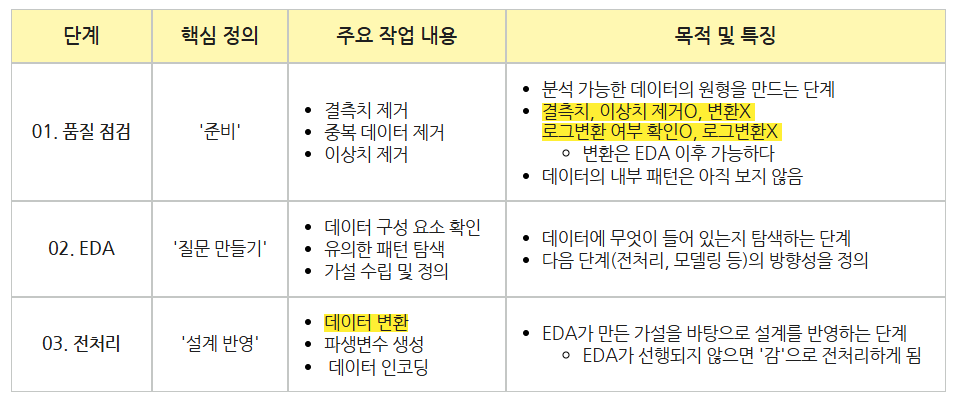

<br>

### (2) 탐색적 데이터 분석(EDA)란?

- EDA 산출물은 **가설**이자, 이 변수를 모델에 넣을 **근거**이다.
- "이 변수가 종속변수와 관련이 있는가?" → 관련이 있으면 **독립변수 후보**가 된다.

    - 변수 채택 근거 4가지

        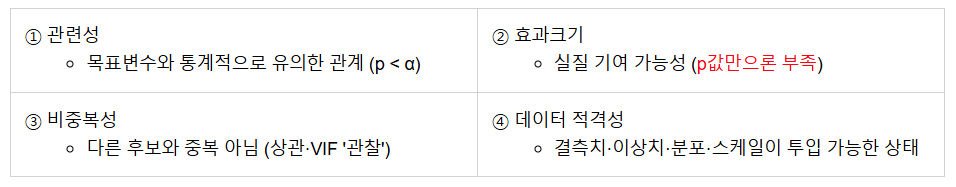

<br>

### (3) 탐색적 데이터 분석(EDA) 파이프라인

- 모델링 전 1차 변수를 선별하는 과정
    - 1단계) 품질 점검(결측치·중복치·이상치 정제)을 완료한 분석을 위한 기본 데이터셋 준비
    - 2단계) 시각화와 추론통계 4종을 거쳐 `"근거 있는 후보군"`을 선정
        - T검정, 상관분석, 분산분석, 교차분석
    - 3단계) 근거있는 후보군을 모델링 단계로 인계

<br>

### (3) 탐색적 데이터 분석(EDA) 분석 유형

- 단변량, 이변량, 다변량 분석

||연속형|명목형|연속형+명목형|
|--|--|--|--|
|**단변량(기술통계량)**|- 시각화 : 히스토그램, KDE, 박스플롯 <br> - 기술통계량 : 평균, 중앙값, 분산, 사분위수|- 시각화 : 막대그래프, 빈도표 <br> - 기술통계량 : 빈도, 비율, 최빈값||
|**이변량(추론통계)**|- 시각화 : 산점도 <br> - 추론통계 : 상관분석 (Pearson, Spearman)|- 시각화 : 교차표 히트맵, 누적막대 <br> - 추론통계 : 교차분석(카이제곱, 피셔의 정확검정)|- 시각화 : 그룹별 박스플롯 <br> - 추론통계 : T검정, 분산분석(ANOVA)|
|**다변량(추론통계)**|- 시각화 : pairplot||- 시각화 : 산점도에 명목형 변수를 hue로 추가|

<br>

### (4) 변수 유형에 따른 검정 방법
- 종속변수에 따른 EDA 기법 분류
    - 독립변수 1개와 종속변수간의 관계를 탐색한다.
    - `연속-연속은 무조건 상관분석, 명목-명목은 무조건 교차분석, 연속-명목/명목-연속은 무조건 T검정 또는 ANOVA검정`

    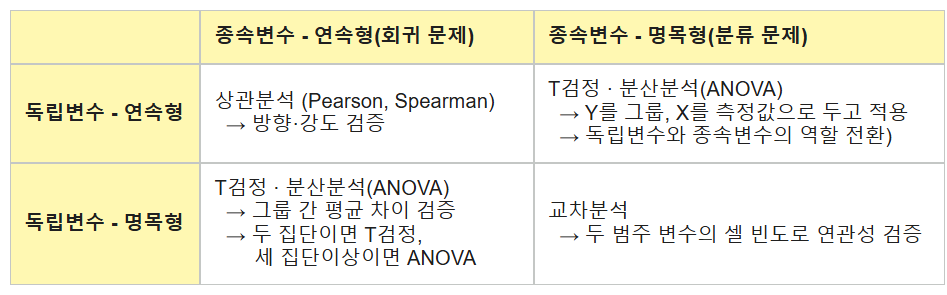

<br>

## 1. 준비작업

### (1) 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.19

⚠️  'jussam' 패키지의 최신 버전이 출시되었습니다! (설치된 버전: 0.5.19, 최신 버전: 0.5.21)
   최신 버전으로 업데이트하려면 다음 명령어를 실행하세요:
   pip install --upgrade jussam



### (2) 품질 점검 완료 데이터 가져오기

- **LAB-05**에서 저장해 둔 데이터셋을 불러온다.

In [2]:
origin = load_data("boston_qtcheck")
origin.head()

📚 보스턴 주택 가격 데이터셋의 품질 검사 완료 버전 (출처: 자체 정제)

    field    description
--  -------  ---------------------------------------------------------------------------------------------
 0  CRIM     타운별 1인당 범죄율 (Per capita crime rate by town)
 1  ZN       25,000 sqft 이상 주거용 대지 비율 (Proportion of residential land zoned for large lots)
 2  INDUS    비소매 상업구역 비율 (Proportion of non-retail business acres per town)
 3  CHAS     명목형, 찰스강 인접 여부 (Charles River dummy variable: 1 if tract bounds river; 0 otherwise)
 4  NOX      대기 오염 정도 (Nitric oxides concentration, parts per 10 million)
 5  RM       주택당 평균 방(Room) 수 (Average number of rooms per dwelling)
 6  AGE      1940년 이전 건축 비율 (Proportion of owner-occupied units built prior to 1940)
 7  DIS      5개 주요 고용센터까지의 거리 (Weighted distances to five Boston employment centers)
 8  RAD      고속도로 접근성 지수 (Index of accessibility to radial highways)
 9  TAX      재산세율 (Full-value property-tax rate per $10,000)
10  PTRATIO  교육구 학생-교사 비율 (Pupil–teacher ratio by town)
11  

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.006,18.000,2.310,0,0.538,6.575,65.200,4.090,1,296,15.300,396.900,4.980,24.000
1,0.027,0.000,7.070,0,0.469,6.421,78.900,4.967,2,242,17.800,396.900,9.140,21.600
2,0.027,0.000,7.070,0,0.469,7.185,61.100,4.967,2,242,17.800,392.830,4.030,34.700
3,0.032,0.000,2.180,0,0.458,6.998,45.800,6.062,3,222,18.700,394.630,2.940,33.400
4,0.069,0.000,2.180,0,0.458,7.147,54.200,6.062,3,222,18.700,396.900,5.330,36.200


### (3) 연속형 변수의 기술 통계량 가져오기

- **LAB-05**에서 저장해 둔 기술 통계량 표를 불러온다.
  - 실제 데이터 분석 프로젝트에서는 엑셀 파일로 저장해 두고 필요할 때 마다 열람하자.

In [3]:
desc = load_data("boston_qtcheck_desc")
desc.T

📚 보스턴 주택 가격 데이터셋의 품질 검사 완료 버전에 대한 기술통계량 표


,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000
mean,3.614,11.364,11.137,0.555,6.285,68.575,3.795,9.549,408.237,18.456,356.674,12.653,22.533
std,8.602,23.322,6.860,0.116,0.703,28.149,2.106,8.707,168.537,2.165,91.295,7.141,9.197
min,0.006,0.000,0.460,0.385,3.561,2.900,1.130,1.000,187.000,12.600,0.320,1.730,5.000
25%,0.082,0.000,5.190,0.449,5.885,45.025,2.100,4.000,279.000,17.400,375.377,6.950,17.025
50%,0.257,0.000,9.690,0.538,6.208,77.500,3.207,5.000,330.000,19.050,391.440,11.360,21.200
75%,3.677,12.500,18.100,0.624,6.623,94.075,5.188,24.000,666.000,20.200,396.225,16.955,25.000
max,88.976,100.000,27.740,0.871,8.780,100.000,12.127,24.000,711.000,22.000,396.900,37.970,50.000
rel_diff,13.087,inf,0.149,0.031,0.012,0.115,0.183,0.910,0.237,0.031,0.089,0.114,0.063
rdiff_flag,large_diff,large_diff,diff,similar,similar,diff,diff,large_diff,diff,similar,similar,diff,similar


>##### [💡 인사이트]
>- 로그변환을 고려해야 할 변수
>   - CRIM, ZN, DIS, RAD, LSTAT, MEDV
>- 역 로그변환을 고려해야 할 변수
>   - B

### (4) 명목형 변수의 기술 통계량 가져오기

- **LAB-05**에서 저장해 둔 기술 통계량 표를 불러온다.
  - 실제 데이터 분석 프로젝트에서는 엑셀 파일로 저장해 두고 필요할 때 마다 열람하자.

In [4]:
cat_desc = load_data("boston_qtcheck_category_desc")
cat_desc

📚 보스턴 주택 가격 데이터셋의 품질 검사 완료 버전에 대한 범주형 변수 기술통계량 표


,CHAS
count,506
unique,2
top,0
freq,471


>##### [💡 인사이트]
>
>- 분포
>   - 명목형 변수 중 유일한 이항 변수이며 **심한 불균형**이다.
>     - 0 : 471/ 1 : 35
>- 분석 시 유의점
>   - 두 집단에 대한 비교인 **T검정**을 쓰되, 표본 불균형으로 **검정력(power)이 낮아질 수 있다**.
>   - 모델 투입 시 한쪽 범주(소수 집단)의 영향이 과소·과대 추정될 수 있어 **해석에 주의해야한다**.
>- 활용
>   - 소수 집단이라도 강변에 인접한 것이 가격에 유의미한 프리미엄을 주는지 확인하면 **해석 가치가 큰 변수**가 될 수 있다(버리지 말고 검정으로 확인).

### (5) 타입 변환 (명목형 확정)

- 명목형 기술통계량 표의 컬럼명이 명목형 변수 목록이다.

In [5]:
df = my_qtcheck.set_type(origin, as_category=cat_desc.columns)

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 non-null    float64 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float64 
 5   RM       506 non-null    float64 
 6   AGE      506 non-null    float64 
 7   DIS      506 non-null    float64 
 8   RAD      506 non-null    int64   
 9   TAX      506 non-null    int64   
 10  PTRATIO  506 non-null    float64 
 11  B        506 non-null    float64 
 12  LSTAT    506 non-null    float64 
 13  MEDV     506 non-null    float64 
dtypes: category(1), float64(11), int64(2)
memory usage: 52.0 KB


>- 'CHAS' 컬럼의 데이터 타입이 category로 변함

### (6) 변수 유형 분류

- EDA 시작 전 **종속변수**와 **변수 유형**을 분류한다.
- **이 분류가 모든 분석 선택을 결정**한다.

In [6]:
# 종속변수
target = "MEDV"
# 종속변수 연속형 여부
target_is_continuous = True

# 명목형 변수
nominal_cols = my_qtcheck.get_categorical_column_names(df)
# 연속형 변수
continuous_cols = my_qtcheck.get_number_column_names(df)

# 종속변수를 독립변수에서 제거
if target_is_continuous:
    # 연속형 변수 이름에서 종속변수 항목 제거
    continuous_cols.remove(target)
else:
    # 명목형 변수 이름에서 종속변수 항목 제거
    nominal_cols.remove(target)

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : MEDV
종속변수 유형: 연속형
명목형   : ['CHAS']
연속형   : ['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


### (7) 컬럼 의미를 정리한 딕셔너리

- 결과 출력시 의미를 함께 표시하기 위해 컬럼 의미를 정리해둔다.

In [7]:
column_means = {
    "CRIM": "범죄율",
    "ZN": "대규모주거지비율",
    "INDUS": "비소매상업지비율",
    "CHAS": "찰스강인접여부",
    "NOX": "대기오염도",
    "RM": "평균방수",
    "AGE": "노후주택비율",
    "DIS": "고용센터거리",
    "RAD": "고속도로접근성",
    "TAX": "재산세율",
    "PTRATIO": "학생교사비율",
    "B": "흑인비율지수",
    "LSTAT": "저소득층비율",
    "MEDV": "주택가격중앙값"
}

### (8) EDA 분류표

- 이 분류의 목적은 **선형회귀·머신러닝 모델에 투입할 독립변수를 채택**하는 것이다.
- 따라서 검정은 두 가지 질문으로 나뉜다.
  - **채택 기준** : 종속변수 × 독립변수 → 이 변수가 **종속변수를 설명하는가**
  - **제거 기준** : 독립변수 × 독립변수 → 이 변수가 **다른 독립변수와 중복인가**
- **변수 유형의 조합이 검정 방법을 결정**한다.
  - `연속-연속은 무조건 상관분석, 명목-명목은 무조건 교차분석, 연속-명목/명목-연속은 무조건 T검정 또는 ANOVA검정`

| 종속유형      | 독립유형      | 분석 유형 | 대상 변수               | 적용 여부 | 비고            |
|-----------|-----------|-------|---------------------|-------|---------------|
| 연속형       | 연속형       | 상관분석  | 연속형 독립변수 12종 → MEDV | ✅ 적용  | 종속·설명 모두 연속형  |
| 연속형       | 명목형(2집단)  | T검정   | CHAS → MEDV         | ✅ 적용  | CHAS가 이진변수(0,1)    |
| 연속형       | 명목형(3집단+) | ANOVA | —                   | ❌ 미적용 | 3집단 이상 명목형 없음 |
| 명목형(2집단)  | 연속형       | T검정   | —                   | ❌ 미적용 | 종속변수 타입이 연속형  |
| 명목형(2집단)  | 명목형(2집단)  | 교차분석  | —                   | ❌ 미적용 | 종속변수 타입이 연속형  |
| 명목형(2집단)  | 명목형(3집단+) | 교차분석  | —                   | ❌ 미적용 | 종속변수 타입이 연속형  |
| 명목형(3집단+) | 연속형       | ANOVA | —                   | ❌ 미적용 | 종속변수 타입이 연속형  |
| 명목형(3집단+) | 명목형(2집단)  | 교차분석  | —                   | ❌ 미적용 | 종속변수 타입이 연속형  |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석  | —                   | ❌ 미적용 | 종속변수 타입이 연속형  |
